# Chapitre 10 - Cours 3 : le consensus et ses multiples visages

Élire un leader sans cerveau divisé, attribuer un nom d'utilisateur une seule fois,
distribuer des identifiants sans trou de sûreté, valider une transaction sur plusieurs
shards : tout cela est facile sur **un** nœud et difficile dès qu'on veut **tolérer les
pannes**. Ce notebook montre que ces problèmes sont **un seul et même problème**, le
**consensus**, en le définissant, en l'implémentant (Paxos à une décision) et en
construisant les réductions qui passent d'une forme à l'autre. Il couvre le début de la
section *Consensus* (encadré *The Impossibility of Consensus*) et *The Many Faces of
Consensus* : *Single-value consensus*, *Compare-and-set as consensus*, *Shared logs as
consensus*, *Fetch-and-add as consensus*, *Atomic commitment as consensus*, ainsi que
*Using shared logs* (section *Consensus in Practice*). Le cours 4 implémente Raft.

**Plan.**

1. Pourquoi le consensus ?
2. Définition : accord, intégrité, validité, terminaison.
3. L'impossibilité FLP, et pourquoi le consensus marche quand même.
4. Le journal partagé (diffusion à ordre total).
5. Compare-and-set et consensus sont équivalents.

6. Fetch-and-add : un consensus à deux seulement.
7. La validation atomique est un consensus.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import consistency as cs
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Pourquoi le consensus ? (section *Consensus*)

Les cours précédents ont accumulé des choses **faciles sur un seul nœud** et difficiles à
rendre tolérantes aux pannes :

| Sur un nœud | Le problème dès qu'on veut tolérer une panne |
|---|---|
| un leader unique, linéarisable | comment basculer sans cerveau divisé ? comment savoir qu'un leader suspendu n'a pas été remplacé ? |
| un compteur `fetch-and-add` qui distribue des identifiants | et s'il tombe en panne ? |
| un CAS atomique pour attribuer un verrou, un bail, un nom unique | une instruction du processeur ; comment la rendre tolérante ? |
| un journal de réplication écrit par le leader | qui décide de l'ordre des entrées si le leader meurt ? |
| valider une transaction sur plusieurs shards (chapitre 8) | tous les participants doivent prendre la même décision |

Toutes ces questions sont des instances d'un même problème fondamental de l'informatique
répartie : le **consensus**, faire **s'accorder plusieurs nœuds sur une valeur**. Il est
réputé difficile à réussir, et beaucoup de systèmes s'y sont trompés. Les algorithmes les
plus connus sont Viewstamped Replication, Paxos, Raft et Zab : proches, mais pas
identiques. Tous supposent un modèle **non byzantin** (les messages peuvent être perdus
ou retardés, les nœuds tomber en panne et redémarrer, mais aucun ne ment). Il existe des
algorithmes tolérant moins d'un tiers de nœuds byzantins (utilisés par les chaînes de
blocs, par exemple), hors du champ du livre (chapitre 9).

> **À retenir.** Leader, verrou, unicité, compteur, journal, validation atomique : le
> même problème, le consensus, se cache derrière chaque « facile sur un nœud ».

## 2. Définition : accord, intégrité, validité, terminaison (section *Single-value consensus*)

Un ou plusieurs nœuds **proposent** des valeurs ; l'algorithme **décide** de l'une
d'elles (l'identifiant du nouveau leader, de l'acheteur du dernier siège, du détenteur
du bail). Formellement, quatre propriétés :

- **accord uniforme** : deux nœuds ne décident jamais différemment ;
- **intégrité** : un nœud ne décide qu'une fois (il ne change pas d'avis) ;
- **validité** : la valeur décidée a été proposée par un nœud (exclut l'algorithme
  trivial qui décide toujours `null`) ;
- **terminaison** : tout nœud qui ne tombe pas en panne finit par décider.

Les trois premières sont des propriétés de **sûreté** (rien de mal n'arrive), la dernière
de **vivacité** (quelque chose de bien finit par arriver ; chapitre 9). Sans
tolérance aux pannes, les trois premières sont triviales : un nœud **dictateur** décide
tout. Mais s'il tombe, plus rien ne se décide. Toute la difficulté est dans la
**terminaison**, qui formalise la tolérance aux pannes : même si des nœuds meurent (et ne
reviennent jamais : imaginez le centre de données enseveli sous un glissement de
terrain), les autres doivent décider. Pour plusieurs décisions (un acheteur par siège),
on exécute une instance par valeur à décider.

**Combien de pannes ?** Si tous les nœuds tombent, rien ne peut se décider. On démontre
qu'un algorithme de consensus a besoin d'une **majorité** de nœuds en état de marche pour
terminer. Intuition : coupez la grappe en deux moitiés égales qui ne se parlent plus ; si
chaque moitié pouvait décider seule, elles pourraient décider différemment. Deux
majorités, elles, ont toujours au moins un nœud en commun : c'est lui qui empêche le
désaccord. Avec $n = 2f + 1$ nœuds, on tolère $f$ pannes. La plupart des algorithmes
garantissent en outre la **sûreté** même quand la majorité est perdue : une grosse panne
arrête le système, elle ne lui fait pas prendre de décisions incohérentes.

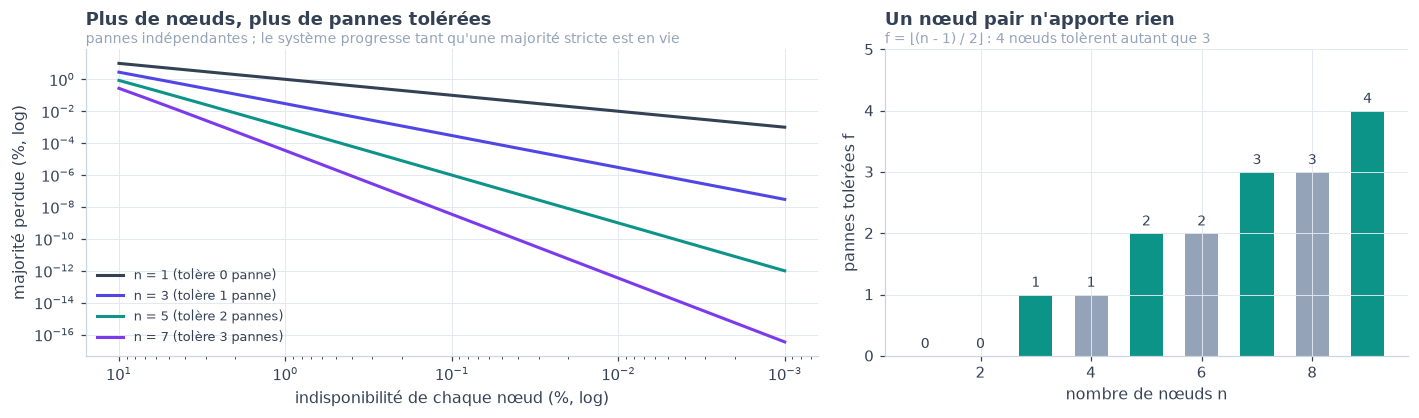

In [2]:
from math import comb

def perte_majorite(n, a):
    """P(moins d'une majorité stricte en vie), calculée directement (sans 1 - x, pour la précision)."""
    q = n // 2 + 1
    return sum(comb(n, k) * a ** k * (1 - a) ** (n - k) for k in range(q))

p = np.linspace(0.9, 0.99999, 400)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw=dict(width_ratios=[1.4, 1]))
for n_, c in [(1, SLATE), (3, INDIGO), (5, TEAL), (7, VIOLET)]:
    ax.plot((1 - p) * 100, [perte_majorite(n_, x) * 100 for x in p], color=c,
            label=f"n = {n_} (tolère {(n_ - 1) // 2} panne{'s' if n_ > 3 else ''})")
ax.set_xscale("log"); ax.set_yscale("log"); ax.invert_xaxis()
ax.set_xlabel("indisponibilité de chaque nœud (%, log)")
ax.set_ylabel("majorité perdue (%, log)")
ax.set_title("Plus de nœuds, plus de pannes tolérées")
subtitle(ax, "pannes indépendantes ; le système progresse tant qu'une majorité stricte est en vie")
ax.legend(loc="lower left", fontsize=8.5)
ns = np.arange(1, 10)
ax2.bar(ns, (ns - 1) // 2, color=[TEAL if n_ % 2 else GRAY for n_ in ns], width=0.6)
annotate_bars(ax2, "{:.0f}")
ax2.set_xlabel("nombre de nœuds n"); ax2.set_ylabel("pannes tolérées f")
ax2.set_title("Un nœud pair n'apporte rien")
subtitle(ax2, "f = ⌊(n - 1) / 2⌋ : 4 nœuds tolèrent autant que 3")
ax2.set_ylim(0, 5)
plt.tight_layout(); plt.show()

**Un algorithme réel : Paxos à une décision.** Pour rendre ces propriétés tangibles,
`cs.run_paxos` implémente le Paxos de Lamport sur le simulateur. Des **proposeurs**
s'adressent à des **accepteurs** en deux phases, chacune auprès d'une **majorité** :

1. *prepare / promise* : le proposeur choisit un numéro de scrutin plus grand que tout ce
   qu'il a vu ; chaque accepteur promet d'ignorer les numéros inférieurs et lui renvoie la
   dernière proposition qu'il a acceptée, s'il y en a une ;
2. *accept / accepted* : le proposeur propose **la valeur acceptée de plus grand numéro
   parmi les réponses** (ou la sienne si aucune) ; si une majorité accepte, la valeur est
   **décidée**.

La règle clé est en phase 2 : un proposeur qui arrive tard **adopte** la valeur
peut-être déjà décidée au lieu d'imposer la sienne. Comme deux majorités se recoupent,
une valeur décidée est forcément vue par tout proposeur ultérieur. Voici deux
proposeurs en compétition sur trois accepteurs.

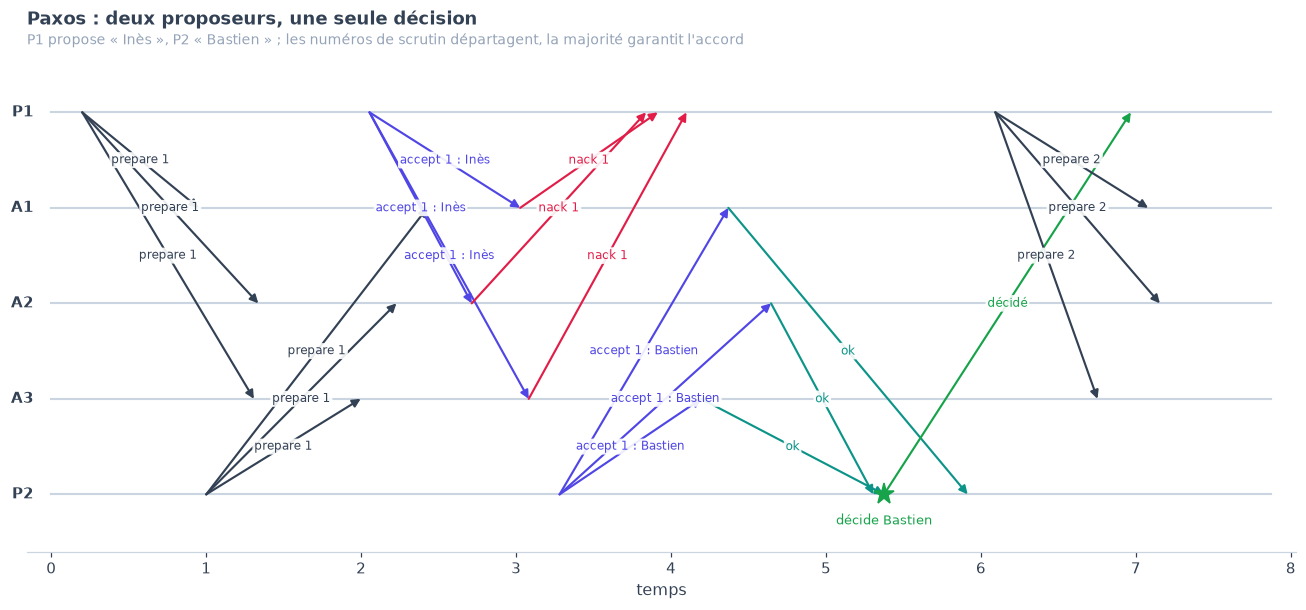

,t,proposer,value,ballot,rounds
0,5.374,P2,Bastien,"(1, P2)",1


In [3]:
net, dec, props = cs.run_paxos({"P1": "Inès", "P2": "Bastien"}, n_acceptors=3, starts={"P1": 0.2, "P2": 1.0},
                               backoff=(2.0, 4.0), latency=(0.6, 1.6), seed=7, until=40)
colors = {"prepare": SLATE, "promise": GRAY, "accept": INDIGO, "accepted": TEAL, "nack": ROSE, "decided": GREEN}
def lab(d):
    m = d.msg
    if m[0] in ("prepare", "nack"):
        return f"{m[0]} {m[1][0]}"
    if m[0] == "accept":
        return f"accept {m[1][0]} : {m[2]}"
    return {"promise": "promise", "accepted": "ok", "decided": "décidé"}[m[0]]
t_end = max(d["t"] for d in dec) + 2.5
st = SpaceTime(["P1", "A1", "A2", "A3", "P2"], t_max=t_end, width=12, title="Paxos : deux proposeurs, une seule décision",
               subtitle="P1 propose « Inès », P2 « Bastien » ; les numéros de scrutin départagent, la majorité garantit l'accord")
st.from_trace([d for d in net.trace if d.t_send < t_end and d.msg[0] != "promise"],
              color_of=lambda d: colors[d.msg[0]], label_of=lab)
for d in dec:
    st.event(d["proposer"], d["t"], f"décide {d['value']}", kind="star", color=GREEN)
st.show()
pd.DataFrame(dec)

Les promesses (en gris) sont omises pour la lisibilité. Les refus (`nack`, en rose)
renvoient un proposeur à une nouvelle tentative avec un numéro plus grand ; une
proposition qui recueille une majorité de `ok` est décidée. Ici, les deux scrutins portent
le numéro 1 et le nom du proposeur départage (P2 > P1) : les accepteurs refusent donc la
proposition de P1. P1 relance un scrutin (`prepare 2`) juste avant de recevoir l'annonce de
la décision ; s'il était allé au bout, la phase 1 lui aurait renvoyé « Bastien », qu'il
aurait proposé à son tour. Vérifions maintenant les propriétés sur 300 exécutions avec trois
proposeurs, cinq accepteurs, des délais aléatoires et **deux accepteurs qui tombent en
panne** en cours de route.

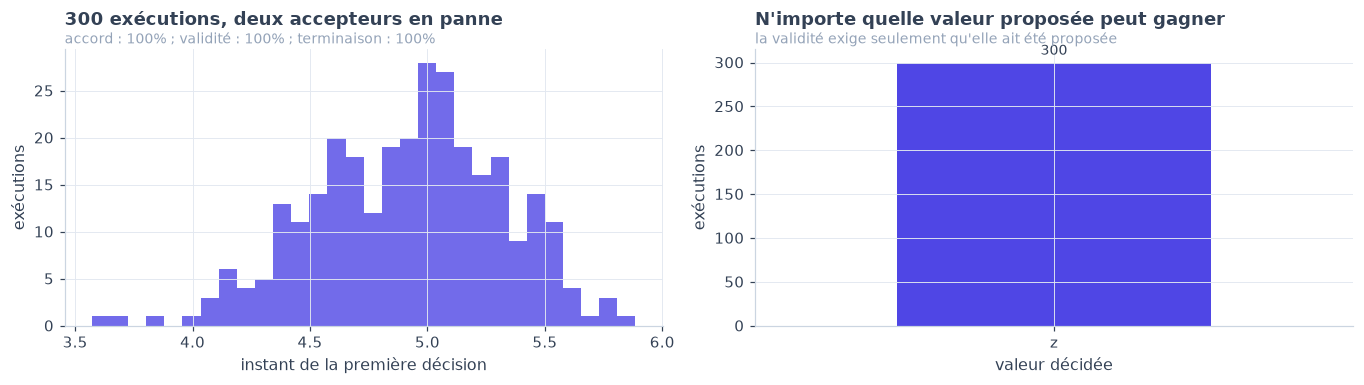

In [4]:
rows = []
for s in range(300):
    net, dec, props = cs.run_paxos({"P1": "x", "P2": "y", "P3": "z"}, n_acceptors=5, seed=s,
                                   starts={"P1": 0, "P2": 0.3, "P3": 0.6}, crashes=[(2.0, "A1"), (3.0, "A2")])
    vals = [p.decided for p in props.values()]
    rows.append(dict(graine=s, accord=len(set(vals)) == 1, validite=set(vals) <= {"x", "y", "z"},
                     termine=all(v is not None for v in vals), t_decision=min(d["t"] for d in dec),
                     tours=sum(p.rounds for p in props.values()), gagnant=vals[0]))
P = pd.DataFrame(rows)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.6))
ax.hist(P.t_decision, bins=30, color=INDIGO, alpha=0.8)
ax.set_xlabel("instant de la première décision"); ax.set_ylabel("exécutions")
ax.set_title("300 exécutions, deux accepteurs en panne")
subtitle(ax, f"accord : {P.accord.mean():.0%} ; validité : {P.validite.mean():.0%} ; terminaison : {P.termine.mean():.0%}")
P.gagnant.value_counts().sort_index().plot.bar(ax=ax2, color=[INDIGO, TEAL, AMBER], rot=0, width=0.55)
annotate_bars(ax2, "{:.0f}")
ax2.set_xlabel("valeur décidée"); ax2.set_ylabel("exécutions")
ax2.set_title("N'importe quelle valeur proposée peut gagner")
subtitle(ax2, "la validité exige seulement qu'elle ait été proposée")
plt.tight_layout(); plt.show()

Dans 100 % des exécutions, les trois proposeurs décident la **même** valeur, toujours une
valeur proposée, et finissent par décider malgré deux accepteurs sur cinq en panne (il
en reste trois, une majorité).

> **À retenir.** Consensus = accord uniforme + intégrité + validité (sûreté) +
> terminaison (vivacité). La terminaison exige une majorité en vie : $2f + 1$ nœuds pour
> tolérer $f$ pannes. Paxos l'obtient avec deux phases de vote majoritaire.

## 3. L'impossibilité FLP, et pourquoi le consensus marche quand même (encadré *The Impossibility of Consensus*)

Le résultat de Fischer, Lynch et Paterson (FLP, 1985) démontre qu'**aucun algorithme
déterministe** ne peut **toujours** atteindre le consensus dans un système
**asynchrone** si un seul nœud peut tomber en panne. Comment discuter d'algorithmes de
consensus, alors ?

- FLP ne dit pas qu'on ne décide **jamais** : seulement qu'on ne peut pas **garantir** la
  terminaison dans tous les cas ;
- il suppose le modèle asynchrone pur : **ni horloge ni délai d'expiration**. Avec des
  délais pour **soupçonner** une panne (même à tort parfois), le consensus devient
  soluble ; il suffit même d'autoriser l'algorithme à tirer des **nombres aléatoires**.

Paxos en donne une illustration concrète : il est toujours **sûr**, mais deux proposeurs
peuvent se **préempter** indéfiniment (chacun invalide le scrutin de l'autre avant qu'il
n'aboutisse). C'est le hasard qui casse la symétrie : comparons cinq proposeurs qui
relancent **immédiatement** après un refus, ou après une attente fixe, ou après une attente
**aléatoire**.

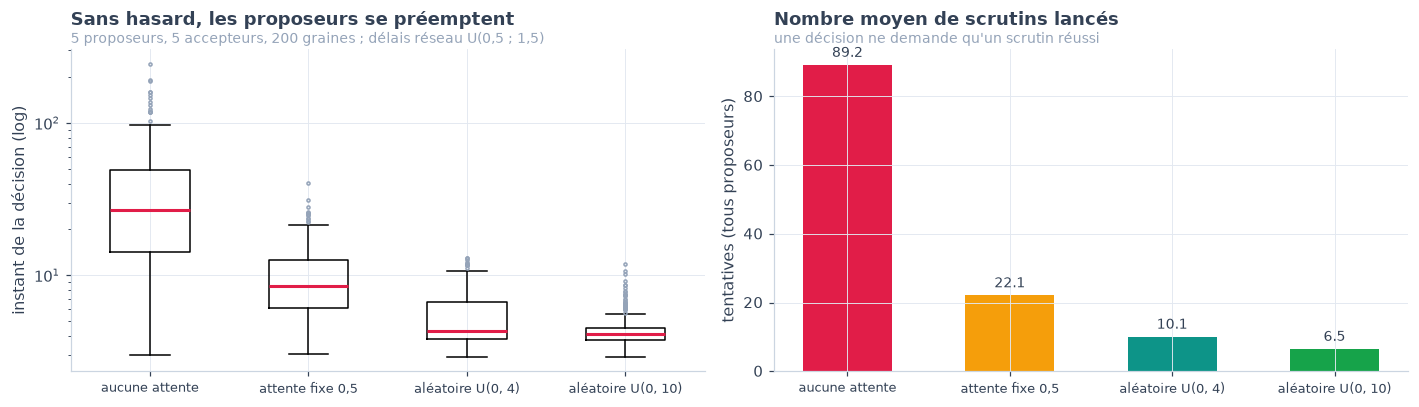

,50%,90%,max
relance,,,
aucune attente,26.641,85.351,243.530
"attente fixe 0,5",8.467,18.398,40.071
"aléatoire U(0, 4)",4.304,9.001,13.070
"aléatoire U(0, 10)",4.090,6.449,11.917


In [5]:
rows = []
for bo, lab_ in [(0.0, "aucune attente"), (0.5, "attente fixe 0,5"), ((0.0, 4.0), "aléatoire U(0, 4)"),
                 ((0.0, 10.0), "aléatoire U(0, 10)")]:
    for s in range(200):
        vals = {f"P{i}": i for i in range(5)}
        net, dec, props = cs.run_paxos(vals, n_acceptors=5, backoff=bo, latency=(0.5, 1.5), seed=s, until=400)
        rows.append(dict(relance=lab_, t=min(d["t"] for d in dec) if dec else np.nan,
                         tours=sum(p.rounds for p in props.values())))
B = pd.DataFrame(rows)
order = ["aucune attente", "attente fixe 0,5", "aléatoire U(0, 4)", "aléatoire U(0, 10)"]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax.boxplot([B[B.relance == o].t for o in order], tick_labels=order, showfliers=True, widths=0.5,
           medianprops=dict(color=ROSE, lw=2), flierprops=dict(marker=".", markersize=4, markeredgecolor=GRAY))
ax.set_yscale("log")
ax.set_ylabel("instant de la décision (log)")
ax.set_title("Sans hasard, les proposeurs se préemptent")
subtitle(ax, "5 proposeurs, 5 accepteurs, 200 graines ; délais réseau U(0,5 ; 1,5)")
ax.tick_params(axis="x", labelsize=8.5)
m = B.groupby("relance").tours.mean().loc[order]
ax2.bar(range(4), m.values, color=[ROSE, AMBER, TEAL, GREEN], width=0.55)
ax2.set_xticks(range(4), order, fontsize=8.5)
annotate_bars(ax2, "{:.1f}")
ax2.set_ylabel("tentatives (tous proposeurs)")
ax2.set_title("Nombre moyen de scrutins lancés")
subtitle(ax2, "une décision ne demande qu'un scrutin réussi")
plt.tight_layout(); plt.show()
B.groupby("relance").t.describe(percentiles=[0.5, 0.9]).loc[order][["50%", "90%", "max"]]

Sans attente, les proposeurs lancent en moyenne près de 90 scrutins pour une seule
décision et certaines exécutions mettent plus de 200 unités de temps à décider : plus on
se bat, plus on se gêne. Une attente **aléatoire** fait que, la plupart du temps, un
proposeur termine ses deux phases avant que les autres ne relancent : décision en 4 à 6
unités. C'est pour cela que Raft tire ses délais d'élection au hasard (cours 4).

> **À retenir.** FLP : pas de terminaison **garantie** pour un algorithme déterministe sans
> horloge. En pratique, délais d'expiration et hasard rendent le consensus soluble, et la
> sûreté, elle, ne dépend jamais des délais.

## 4. Le journal partagé (sections *Shared logs as consensus* et *Using shared logs*)

Nous avons croisé beaucoup de journaux : journal de réplication, journal de
transactions, journal d'écriture anticipée. Un **journal partagé** est un journal où
**plusieurs** nœuds peuvent demander l'ajout d'entrées, et que tous lisent dans le **même
ordre**. C'est exactement la réplication à leader unique : n'importe quel client demande
une écriture au leader, qui l'ajoute au journal, et tous les suiveurs appliquent les
écritures dans le même ordre. On le formalise par la **diffusion à ordre total** (total
order broadcast, ou atomic broadcast) : « diffuser » une valeur, c'est demander son
ajout ; quand le protocole la « délivre », elle devient une entrée lisible. Les
propriétés :

- **ajout à terme** : un nœud qui demande l'ajout d'une valeur et ne tombe pas en panne
  finit par la lire dans le journal ;
- **livraison fiable** : aucune entrée perdue ; si un nœud lit une entrée, tout nœud qui ne
  tombe pas en panne finira par la lire ;
- **ajout seulement** (append-only) : une entrée lue ne change plus, et les nouvelles se
  placent **après** ; relire donne la même suite, même après un redémarrage ;
- **accord** : deux nœuds qui lisent une entrée $e$ ont lu exactement les mêmes entrées
  avant $e$, dans le même ordre ;
- **validité** : toute entrée lue a été demandée par un nœud.

**Pourquoi c'est puissant.** Si chaque entrée est une écriture et que chaque réplique
applique les mêmes écritures dans le même ordre avec une logique **déterministe**, toutes
les répliques aboutissent au même état : c'est la **réplication de machine à états**
(state machine replication), principe de l'event sourcing (chapitre 3). Si chaque entrée est une transaction
déterministe (procédure stockée) exécutée dans l'ordre du journal, on obtient des
transactions **sérialisables** (exécution en série, chapitre 8). Le journal
sert aussi au traitement de flux (chapitre 12).

**Démonstration : un registre de noms d'utilisateur.** Trois personnes réclament « bob »
sur trois répliques à quelques dixièmes d'unité de temps d'intervalle. Sans ordre total,
chaque réplique applique les demandes dans leur ordre d'**arrivée** ; avec un séquenceur
(un leader qui numérote les entrées), dans l'ordre du **journal** (`cs.run_registry`).

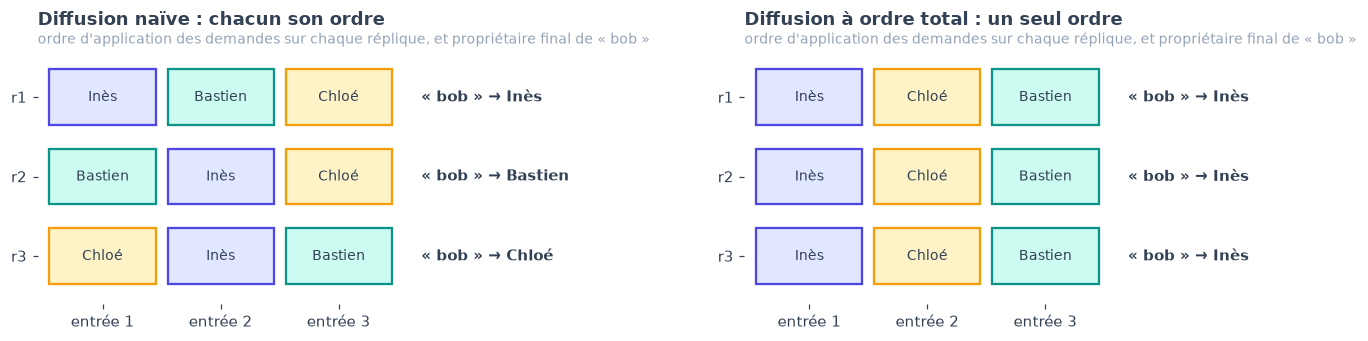

In [6]:
claims = [(1.0, "r1", "bob", "Inès"), (1.2, "r2", "bob", "Bastien"), (1.1, "r3", "bob", "Chloé")]
res = {}
for mode in (False, True):
    net, reps = cs.run_registry(claims, total_order=mode, latency=(0.5, 4.0), seed=3)
    res[mode] = (net, reps)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
for ax, mode in zip(axes, (False, True)):
    net, reps = res[mode]
    for i, r in enumerate(reps):
        for k, (entry, t) in enumerate(zip(r.log, r.apply_times)):
            c = {"Inès": INDIGO, "Bastien": TEAL, "Chloé": AMBER}[entry[2]]
            ax.add_patch(plt.Rectangle((k, 2 - i - 0.35), 0.9, 0.7, facecolor=LIGHT[c], edgecolor=c, lw=1.5))
            ax.text(k + 0.45, 2 - i, entry[2], ha="center", va="center", fontsize=9, color=SLATE)
        ax.text(3.15, 2 - i, f"« bob » → {r.owner['bob']}", va="center", fontsize=9.5, color=SLATE, fontweight="bold")
    ax.set_xlim(-0.1, 4.6); ax.set_ylim(-0.6, 2.6)
    ax.set_yticks([2, 1, 0], ["r1", "r2", "r3"]); ax.set_xticks([0.45, 1.45, 2.45], ["entrée 1", "entrée 2", "entrée 3"])
    ax.grid(False)
    for s_ in ("left", "bottom"):
        ax.spines[s_].set_visible(False)
    ax.set_title("Diffusion naïve : chacun son ordre" if not mode else "Diffusion à ordre total : un seul ordre")
    subtitle(ax, "ordre d'application des demandes sur chaque réplique, et propriétaire final de « bob »")
plt.tight_layout(); plt.show()

Avec la diffusion naïve, chaque réplique donne « bob » à la première demande **reçue** :
trois répliques, trois propriétaires différents, une contrainte d'unicité violée. Avec
l'ordre total, toutes appliquent la même suite et donnent « bob » à la même personne. On
obtient ainsi un **CAS linéarisable** : pour réserver un nom, on ajoute au journal « je
réclame bob », on lit le journal jusqu'à retrouver sa propre entrée, et l'on a gagné si
aucune réclamation de « bob » ne la précède. Les lectures aussi peuvent être
linéarisées en passant par le journal (ajouter un marqueur et attendre de le lire).

**Du consensus au journal et retour.** Avec un journal partagé, le consensus est
immédiat : chacun ajoute sa proposition et l'on décide **la première entrée** (tout le
monde lit les entrées dans le même ordre). Réciproquement, avec un algorithme de
consensus, on construit un journal : une instance de consensus par **case** du journal ;
pour ajouter une valeur, on la propose pour la première case non décidée ; si elle
perd, on recommence pour la suivante ; une case décidée est délivrée dès que toutes les
précédentes le sont. C'est l'idée de **Multi-Paxos**. Le journal partagé est donc
**équivalent** au consensus. Le séquenceur de la démonstration ne l'est pas tout à fait :
s'il tombe, plus rien n'est délivré (la vivacité est perdue). Tout l'enjeu est de
**remplacer le leader** automatiquement et sans danger : c'est ce que fait Raft.

> **À retenir.** Un journal partagé (diffusion à ordre total) ordonne toutes les entrées
> de la même façon pour tous : il donne la réplication de machine à états, les
> transactions sérialisables, un CAS linéarisable. Il est équivalent au consensus ; la
> difficulté est de le garder vivant quand son leader tombe.

## 5. Compare-and-set et consensus sont équivalents (section *Compare-and-set as consensus*)

**Du CAS au consensus.** Avec un CAS linéarisable et tolérant aux pannes, c'est immédiat :
l'objet vaut initialement `null` ; chaque proposeur exécute `cas(null, sa_valeur)` ; la
valeur décidée est celle que contient l'objet. Le premier CAS réussit, tous les autres
échouent et lisent le gagnant.

**Du consensus au CAS.** Pour des CAS concurrents de même valeur attendue, on propose
leurs nouvelles valeurs au consensus et l'on écrit la valeur décidée ; les CAS dont la
valeur n'a pas été retenue échouent. Des valeurs attendues différentes utilisent des
instances séparées. Les deux réductions tiennent en quelques lignes.

In [7]:
class RegistreCAS:
    """CAS linéarisable (ici sur un seul nœud : c'est la tolérance aux pannes qui est difficile)."""
    def __init__(self):
        self.valeur = None
    def cas(self, attendu, nouveau):
        if self.valeur == attendu:
            self.valeur = nouveau
            return True
        return False

def consensus_par_cas(propositions, ordre_arrivee):
    reg = RegistreCAS()
    for p in ordre_arrivee:
        reg.cas(None, propositions[p])
    return {p: reg.valeur for p in propositions}      # chacun décide la valeur de l'objet

def cas_par_consensus(decider, valeur_courante, demandes):
    """demandes : {client: (attendu, nouveau)} ; decider : fonction de consensus."""
    ok = {c: False for c in demandes}
    candidats = {c: nv for c, (att, nv) in demandes.items() if att == valeur_courante}
    if not candidats:
        return valeur_courante, ok
    gagnant = decider(candidats)
    for c, nv in candidats.items():
        ok[c] = nv == gagnant
    return gagnant, ok

print("consensus par CAS :", consensus_par_cas({"P1": "x", "P2": "y", "P3": "z"}, ["P2", "P3", "P1"]))
def decider_paxos(cands):
    _, _, props = cs.run_paxos({c: v for c, v in cands.items()}, n_acceptors=3, seed=11)
    return next(iter(props.values())).decided
print("CAS par consensus (Paxos) :", cas_par_consensus(decider_paxos, 0, {"c1": (0, 5), "c2": (0, 7), "c3": (3, 9)}))

consensus par CAS : {'P1': 'y', 'P2': 'y', 'P3': 'y'}
CAS par consensus (Paxos) : (7, {'c1': False, 'c2': True, 'c3': False})


Le CAS de `c3` échoue d'office (il attendait 3, la valeur vaut 0) ; Paxos départage `c1`
et `c2`. CAS et consensus sont donc **équivalents** : faciles sur un nœud, difficiles à
rendre tolérants aux pannes. Un exemple de CAS en environnement distribué : les écritures conditionnelles des magasins d'objets (chapitre 4), qui n'écrivent un objet que s'il n'a pas été créé ou modifié par quelqu'un d'autre depuis la dernière lecture.

> **À retenir.** Un CAS linéarisable tolérant aux pannes résout le consensus (premier CAS
> depuis `null`), et le consensus implémente le CAS : les deux problèmes sont équivalents.

## 6. Fetch-and-add : un consensus à deux seulement (section *Fetch-and-add as consensus*)

Le générateur d'identifiants linéarisable du cours 2 repose sur `fetch-and-add`
(incrémenter et renvoyer l'ancienne valeur). Avec un CAS, on l'implémente facilement
(lire, puis `cas(lu, lu + 1)`, recommencer en cas d'échec). Mais la réciproque ? Chaque
proposeur fait `fetch-and-add` ; celui qui lit 0 a gagné. Lui le sait ; les autres savent
qu'ils ont perdu, mais **pas qui a gagné**. Si le gagnant tombe avant de le leur dire, ils
restent bloqués, et ils ne peuvent pas se rabattre sur un autre : le gagnant pourrait
revenir et décider, à juste titre, sa propre valeur.

Avec **deux** proposeurs seulement, cela marche : chacun annonce d'abord sa valeur à
l'autre, puis fait `fetch-and-add` ; celui qui lit 0 décide la sienne, celui qui lit 1
décide celle de l'autre. On dit que `fetch-and-add` a un **nombre de consensus** de 2,
contre l'infini pour le CAS et le journal partagé. Simulons trois proposeurs dont le
gagnant tombe en panne juste après son `fetch-and-add`.

In [8]:
def fetch_and_add_consensus(propositions, ordre, panne=None, annonces=True):
    compteur = {"v": 0}
    vus = {p: {} for p in propositions}
    if annonces:                         # étape 1 : chacun annonce sa valeur à tous
        for p in propositions:
            for q in propositions:
                vus[q][p] = propositions[p]
    lu, decision = {}, {}
    for p in ordre:                      # étape 2 : fetch-and-add atomique
        lu[p] = compteur["v"]; compteur["v"] += 1
    for p in ordre:
        if p == panne:
            continue
        if lu[p] == 0:
            decision[p] = propositions[p]
        elif len(propositions) == 2:
            autre = next(q for q in propositions if q != p)
            decision[p] = vus[p][autre]
        else:
            gagnant = [q for q in ordre if lu[q] == 0][0]
            decision[p] = "bloqué : qui a lu 0 ?" if gagnant == panne else f"attend l'annonce de {gagnant}"
    return lu, decision

for props_, ordre, panne in [({"P1": "x", "P2": "y"}, ["P2", "P1"], "P2"),
                             ({"P1": "x", "P2": "y", "P3": "z"}, ["P3", "P1", "P2"], "P3")]:
    lu, dec = fetch_and_add_consensus(props_, ordre, panne)
    print(f"{len(props_)} proposeurs, {panne} (qui lit 0) tombe en panne : lu = {lu} -> décisions = {dec}")

2 proposeurs, P2 (qui lit 0) tombe en panne : lu = {'P2': 0, 'P1': 1} -> décisions = {'P1': 'y'}
3 proposeurs, P3 (qui lit 0) tombe en panne : lu = {'P3': 0, 'P1': 1, 'P2': 2} -> décisions = {'P1': 'bloqué : qui a lu 0 ?', 'P2': 'bloqué : qui a lu 0 ?'}


À deux, le survivant qui lit 1 sait que l'autre a lu 0 et connaît sa valeur : il décide
« y » même si P2 est mort. À trois, P1 et P2 savent seulement qu'ils ont perdu : ils
ignorent lequel des deux autres a lu 0, et le seul qui le sait est en panne. La
terminaison est perdue.

> **À retenir.** Fetch-and-add ne résout le consensus qu'entre deux nœuds (nombre de
> consensus 2) ; CAS et journal partagé le résolvent pour n'importe quel nombre.

## 7. La validation atomique est un consensus (section *Atomic commitment as consensus*)

La validation atomique d'une transaction répartie (chapitre 8, validation à
deux phases) ressemble au consensus, avec une différence : on ne peut pas décider
« n'importe quelle valeur proposée » ; si **un seul** participant vote « annuler », tous
doivent annuler. Ses propriétés :

| Propriété | Validation atomique | Consensus |
|---|---|---|
| accord uniforme | pas de nœud qui valide pendant qu'un autre annule | pas deux décisions différentes |
| intégrité | on ne revient pas sur sa décision | idem |
| validité | valider seulement si **tous** ont voté oui ; un non impose l'annulation | décider une valeur proposée |
| non-trivialité | si tous votent oui et qu'aucun délai n'expire, valider | (pas d'équivalent) |
| terminaison | tout nœud vivant finit par valider ou annuler | idem |

La non-trivialité interdit l'algorithme qui annule toujours, tout en autorisant
l'annulation en cas de délai dépassé.

**Du consensus à la validation atomique.** Chaque participant envoie son vote à tous ;
celui qui reçoit « oui » de tout le monde (y compris de lui-même) propose « valider » au
consensus ; celui qui reçoit un « non » ou subit un délai dépassé propose « annuler ».
Tous appliquent la décision du consensus. « Valider » n'est proposé que si tous ont voté
oui ; si les votes sont tous oui mais qu'un message a tardé, certains proposent
« annuler » et d'autres « valider » : peu importe, tant que tous font la même chose.

In [9]:
def validation_atomique(votes, delai_depasse=frozenset(), seed=0):
    participants = list(votes)
    propositions = {}
    for p in participants:
        recu_tous_oui = all(votes[q] for q in participants) and p not in delai_depasse
        propositions[p] = "valider" if recu_tous_oui else "annuler"
    g = np.random.default_rng(seed)
    starts = {p: float(g.uniform(0, 3)) for p in participants}    # les votes n'arrivent pas en même temps
    _, _, props = cs.run_paxos(propositions, n_acceptors=3, seed=seed, starts=starts)
    return propositions, {p: pr.decided for p, pr in props.items()}

cas_ = {"tous oui": ({"S1": True, "S2": True, "S3": True}, frozenset()),
        "S2 vote non": ({"S1": True, "S2": False, "S3": True}, frozenset()),
        "tous oui, mais S3 n'a pas reçu le vote de S1 à temps": ({"S1": True, "S2": True, "S3": True}, frozenset({"S3"}))}
rows = []
for nom, (votes, delai) in cas_.items():
    for seed in range(20):
        props_, dec = validation_atomique(votes, delai, seed=seed)
        rows.append(dict(scénario=nom, propositions=" / ".join(props_.values()),
                         décision=" / ".join(sorted(set(dec.values())))))
pd.DataFrame(rows).value_counts().rename("graines (sur 20)").reset_index()

,scénario,propositions,décision,graines (sur 20)
0,tous oui,valider / valider / valider,valider,20
1,S2 vote non,annuler / annuler / annuler,annuler,20
2,"tous oui, mais S3 n'a pas reçu le vote de S1 à...",valider / valider / annuler,annuler,19
3,"tous oui, mais S3 n'a pas reçu le vote de S1 à...",valider / valider / annuler,valider,1


Les deux premiers scénarios sont déterministes ; dans le troisième, le consensus retient
selon les délais tantôt « annuler » (19 graines sur 20 ici), tantôt « valider », mais
**tous les participants font toujours la même chose**. À l'inverse, un protocole de validation atomique **tolérant aux pannes**
résout le consensus : chaque proposeur lance une transaction sur un quorum de nœuds, qui
fait un CAS local « si le registre est vide, y mettre ma valeur » et vote oui si le CAS
réussit ; si la transaction est validée, sa valeur est décidée, sinon le proposeur
recommence. Les deux problèmes sont donc équivalents. La validation à deux phases, avec
son coordinateur point de défaillance unique, n'est pas tolérante aux pannes ; les bases
distribuées modernes la combinent avec un consensus (chaque participant étant un groupe
répliqué par consensus) pour éviter les blocages.

> **À retenir.** Validation atomique et consensus sont équivalents, à la nuance près
> qu'un seul « non » impose l'annulation. Le consensus résout la validation atomique en
> décidant entre « valider » et « annuler ».

## Synthèse

- Leader, verrou, unicité, journal, compteur, validation atomique : tous se ramènent au
  **consensus**, s'accorder sur une valeur avec **accord, intégrité, validité** (sûreté)
  et **terminaison** (vivacité).
- La terminaison exige une **majorité** de nœuds en vie : $2f + 1$ nœuds tolèrent $f$
  pannes. Paxos l'obtient avec deux phases de vote majoritaire, sûres dans tous les cas.
- **FLP** interdit de garantir la terminaison sans horloge ni hasard ; en pratique,
  délais et attentes aléatoires suffisent (on l'a mesuré sur les duels de Paxos).
- Le **journal partagé** (diffusion à ordre total) est la forme la plus utile : réplication
  de machine à états, transactions sérialisables, CAS linéarisable.
- Équivalences : consensus ⇔ journal partagé ⇔ CAS linéarisable ⇔ validation atomique ; fetch-and-add ne vaut que pour deux nœuds.

Liens : la réplication à leader unique au chapitre 6, les transactions
au chapitre 8, les modèles de système et la détection de pannes au chapitre
9, les journaux au chapitre 12. Le cours suivant implémente **Raft**, qui
fournit un journal partagé tolérant aux pannes.